# ExAI-PanC: journal-level results and evaluation

This notebook is fully self-contained and is intended to be run cell by cell from top to bottom. It produces publication-ready tables, quality-control summaries, and figures directly in the notebook.

The workflow is conservative: a predictive metric is only reported as a result when held-out labels and predictions are available. Stored model metadata is shown for provenance, never presented as independent test performance.

## Reporting guardrails

- All CT results are case-level, not slice-level.
- Classification threshold is prespecified at 0.50; it is not optimized on the test set.
- Independent test predictions are preferred. If only exploratory predictions are supplied, the status is labelled accordingly.
- Confidence intervals use a fixed-seed non-parametric bootstrap.
- Dice, IoU, sensitivity, specificity, and HD95 are computed for segmentation.
- Accuracy, balanced accuracy, precision, recall, specificity, F1, ROC-AUC, average precision, and Brier score are computed for classification.
- Survival analysis requires subject-level time-to-event outcomes and risk predictions; C-index, time-dependent AUC, and Brier score are not inferred from absent data.

In [1]:
from pathlib import Path
import hashlib
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nibabel as nib
from scipy import ndimage
from IPython.display import display, Markdown
ROOT = Path.cwd()
while not (ROOT / 'DATASETS').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
DATA_DIR = ROOT / 'DATASETS' / 'MSD_Pancreas'
MODEL_DIR = ROOT / 'models'
OUTPUT_DIR = ROOT / 'notebooks' / 'publication_outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SEED = 2026
rng = np.random.default_rng(SEED)
sns.set_theme(style='whitegrid', context='talk')
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 300})
print(f'Root: {ROOT}')
print(f'Output folder: {OUTPUT_DIR}')

Root: C:\Users\Cdac\Desktop\XAI-PanC\XAI-PanC
Output folder: C:\Users\Cdac\Desktop\XAI-PanC\XAI-PanC\notebooks\publication_outputs


## 1. Dataset inventory

In [2]:
def nii_stem(path):
    return path.name[:-7] if path.name.endswith('.nii.gz') else path.stem
image_files = sorted((DATA_DIR / 'imagesTr').glob('*.nii*'))
label_files = sorted((DATA_DIR / 'labelsTr').glob('*.nii*'))
images = {nii_stem(p): p for p in image_files}
labels = {nii_stem(p).removesuffix('_label'): p for p in label_files}
paired_cases = sorted(set(images) & set(labels))
unpaired_images = sorted(set(images) - set(labels))
unpaired_labels = sorted(set(labels) - set(images))
if unpaired_images or unpaired_labels: warnings.warn(f'Unpaired files: images={unpaired_images}, labels={unpaired_labels}')
inventory = pd.DataFrame({'quantity': ['CT images', 'label volumes', 'paired cases', 'unpaired CT images', 'unpaired labels'], 'count': [len(images), len(labels), len(paired_cases), len(unpaired_images), len(unpaired_labels)]})
display(inventory)
assert paired_cases, 'No paired NIfTI cases found.'

,quantity,count
0,CT images,5
1,label volumes,5
2,paired cases,5
3,unpaired CT images,0
4,unpaired labels,0


## 2. Case-level CT and label quality control

In [3]:
def robust_percentiles(array, q=(1, 50, 99), max_values=100_000):
    values = np.asarray(array, dtype=np.float32); values = values[np.isfinite(values)]
    if values.size > max_values: values = values[::max(1, values.size // max_values)]
    return np.percentile(values, q) if values.size else [np.nan] * len(q)
case_rows = []
for case_id in paired_cases:
    image_obj = nib.load(str(images[case_id])); label_obj = nib.load(str(labels[case_id]))
    image = np.asanyarray(image_obj.dataobj); label = np.asanyarray(label_obj.dataobj)
    if image.shape != label.shape: raise ValueError(f'{case_id}: image shape {image.shape} != label shape {label.shape}')
    spacing = np.sqrt((image_obj.affine[:3, :3] ** 2).sum(axis=0)); voxel_mm3 = float(np.prod(spacing))
    p01, p50, p99 = robust_percentiles(image); pancreas = label > 0; tumour = label == 2
    case_rows.append({'case_id': case_id, 'shape': ' x '.join(map(str, image.shape)), 'spacing_x_mm': spacing[0], 'spacing_y_mm': spacing[1], 'spacing_z_mm': spacing[2], 'voxel_volume_mm3': voxel_mm3, 'ct_p01': p01, 'ct_median': p50, 'ct_p99': p99, 'pancreas_voxels': int(pancreas.sum()), 'tumour_voxels': int(tumour.sum()), 'pancreas_volume_cm3': pancreas.sum() * voxel_mm3 / 1000, 'tumour_volume_cm3': tumour.sum() * voxel_mm3 / 1000, 'unique_label_values': ', '.join(map(str, np.unique(label).astype(int)))})
case_table = pd.DataFrame(case_rows).sort_values('case_id').reset_index(drop=True)
case_table.to_csv(OUTPUT_DIR / 'case_level_qc.csv', index=False)
display(case_table.style.format({'spacing_x_mm': '{:.3f}', 'spacing_y_mm': '{:.3f}', 'spacing_z_mm': '{:.3f}', 'voxel_volume_mm3': '{:.3f}', 'pancreas_volume_cm3': '{:.2f}', 'tumour_volume_cm3': '{:.2f}'}))
display(pd.DataFrame({'summary': ['tumour volume minimum (cm³)', 'tumour volume median (cm³)', 'tumour volume maximum (cm³)', 'cases with labels 0/1/2'], 'value': [case_table.tumour_volume_cm3.min(), case_table.tumour_volume_cm3.median(), case_table.tumour_volume_cm3.max(), int((case_table.unique_label_values == '0, 1, 2').sum())]}))

,case_id,shape,spacing_x_mm,spacing_y_mm,spacing_z_mm,voxel_volume_mm3,ct_p01,ct_median,ct_p99,pancreas_voxels,tumour_voxels,pancreas_volume_cm3,tumour_volume_cm3,unique_label_values
0,pancreas_001,512 x 512 x 110,0.645,0.645,2.500,1.039,-1024.000000,-122.000000,287.760000,65710,26153,68.24,27.16,"0, 1, 2"
1,pancreas_010,512 x 512 x 174,0.977,0.977,1.500,1.431,-1024.000000,-728.000000,193.000000,169684,53193,242.73,76.09,"0, 1, 2"
2,pancreas_219,512 x 512 x 192,0.977,0.977,2.500,2.384,-1024.000000,-869.000000,264.000000,42315,4020,100.89,9.58,"0, 1, 2"
3,pancreas_409,512 x 512 x 751,0.787,0.787,0.700,0.434,-2048.000000,-697.000000,371.000000,557595,324028,241.82,140.53,"0, 1, 2"
4,pancreas_414,512 x 512 x 169,0.977,0.977,1.250,1.192,-1024.000000,-979.000000,229.000000,127662,76733,152.18,91.47,"0, 1, 2"


,summary,value
0,tumour volume minimum (cm³),9.584418
1,tumour volume median (cm³),76.093123
2,tumour volume maximum (cm³),140.526367
3,cases with labels 0/1/2,5.000000


## 3. Publication figures

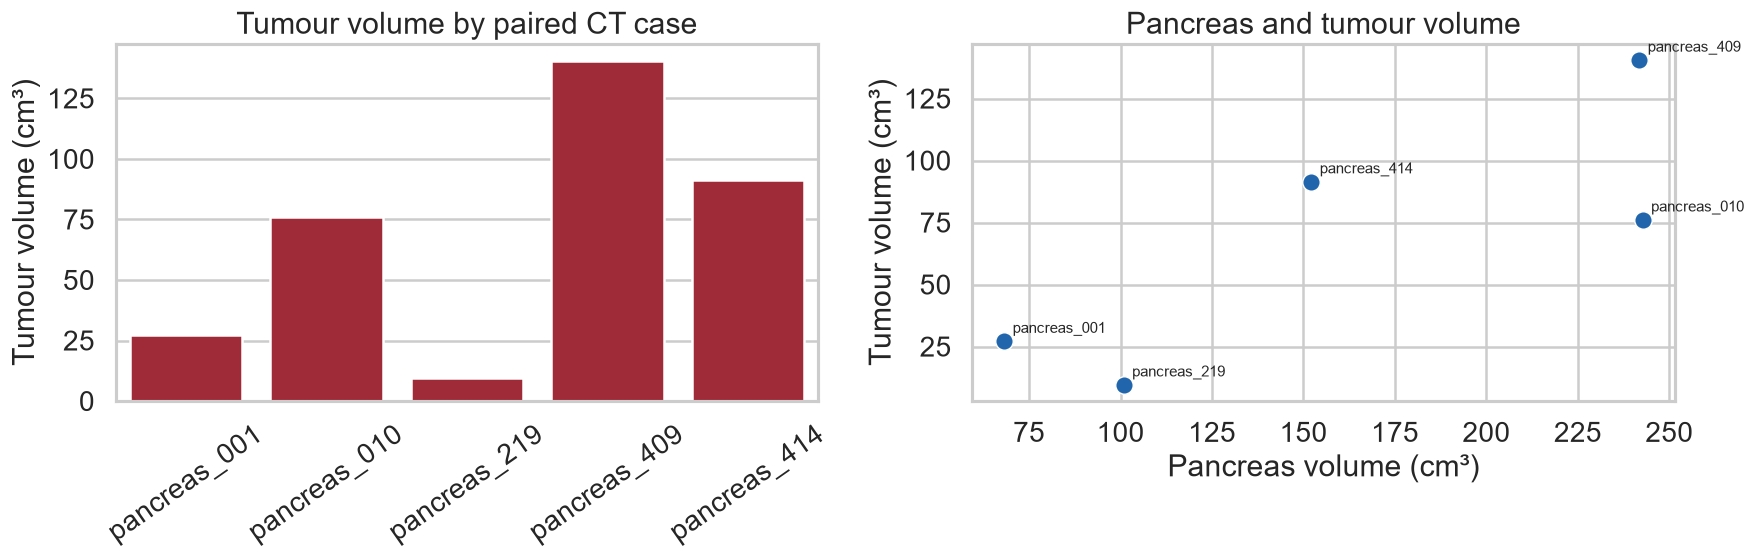

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=case_table, x='case_id', y='tumour_volume_cm3', ax=axes[0], color='#b2182b')
axes[0].set(title='Tumour volume by paired CT case', xlabel='', ylabel='Tumour volume (cm³)'); axes[0].tick_params(axis='x', rotation=35)
sns.scatterplot(data=case_table, x='pancreas_volume_cm3', y='tumour_volume_cm3', s=110, ax=axes[1], color='#2166ac')
for _, row in case_table.iterrows(): axes[1].annotate(row.case_id, (row.pancreas_volume_cm3, row.tumour_volume_cm3), xytext=(5, 5), textcoords='offset points', fontsize=9)
axes[1].set(title='Pancreas and tumour volume', xlabel='Pancreas volume (cm³)', ylabel='Tumour volume (cm³)'); fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'figure_1_case_level_volumes.png', bbox_inches='tight'); plt.show()

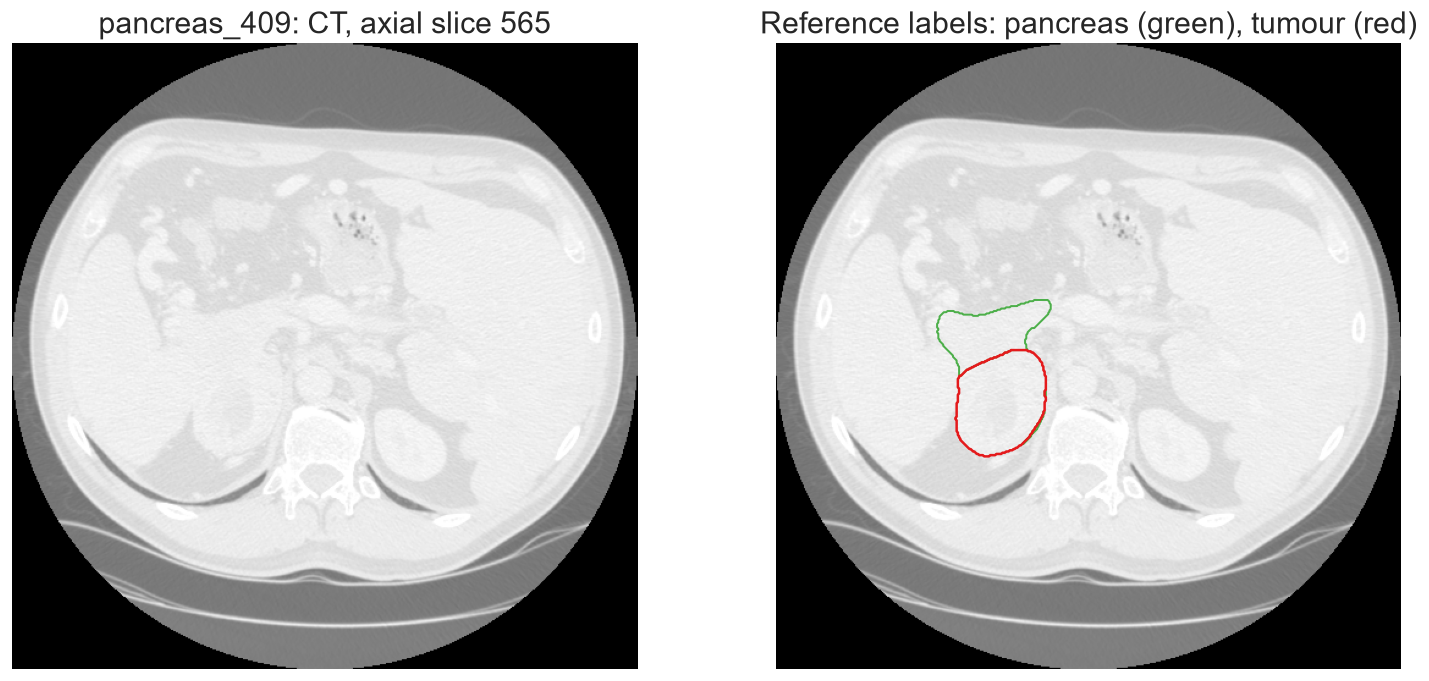

In [5]:
representative_case = case_table.loc[case_table.tumour_volume_cm3.idxmax(), 'case_id']
image = np.asanyarray(nib.load(str(images[representative_case])).dataobj); label = np.asanyarray(nib.load(str(labels[representative_case])).dataobj)
slice_idx = int(np.argmax((label == 2).sum(axis=(0, 1)))); slice_image = np.rot90(image[:, :, slice_idx]); slice_label = np.rot90(label[:, :, slice_idx]); vmin, _, vmax = robust_percentiles(slice_image)
fig, axes = plt.subplots(1, 2, figsize=(13, 6)); axes[0].imshow(slice_image, cmap='gray', vmin=vmin, vmax=vmax); axes[0].set_title(f'{representative_case}: CT, axial slice {slice_idx}')
axes[1].imshow(slice_image, cmap='gray', vmin=vmin, vmax=vmax); axes[1].contour(slice_label == 1, levels=[0.5], colors='#4daf4a', linewidths=1.2); axes[1].contour(slice_label == 2, levels=[0.5], colors='#e41a1c', linewidths=1.5); axes[1].set_title('Reference labels: pancreas (green), tumour (red)')
for ax in axes: ax.axis('off')
fig.tight_layout(); fig.savefig(OUTPUT_DIR / 'figure_2_representative_ct_overlay.png', bbox_inches='tight'); plt.show()

## 4. Model-artifact audit

The stored metadata reports detection AUC and accuracy of 1.00 on 183 TCGA and 362 GTEx samples. Since the repository does not contain the source feature matrix, subject-level predictions, or a verifiable held-out split, these values are retained as provenance only.

In [6]:
metadata_path = MODEL_DIR / 'metadata.json'; model_metadata = json.loads(metadata_path.read_text(encoding='utf-8')) if metadata_path.exists() else {}
manifest_rows = []
for path in sorted(MODEL_DIR.iterdir()):
    if path.is_file(): manifest_rows.append({'file': path.name, 'size_mb': path.stat().st_size / 1024**2, 'sha256_12': hashlib.sha256(path.read_bytes()).hexdigest()[:12]})
artifact_manifest = pd.DataFrame(manifest_rows); artifact_manifest.to_csv(OUTPUT_DIR / 'model_artifact_manifest.csv', index=False)
model_audit = pd.DataFrame([{'task': 'Detection', 'metric': 'ROC-AUC', 'stored_value': model_metadata.get('detection_auc'), 'n_tcga': model_metadata.get('n_tcga'), 'n_gtex': model_metadata.get('n_gtex'), 'status': 'TRAINING METADATA ONLY; not a held-out test result'}, {'task': 'Detection', 'metric': 'Accuracy', 'stored_value': model_metadata.get('detection_acc'), 'n_tcga': model_metadata.get('n_tcga'), 'n_gtex': model_metadata.get('n_gtex'), 'status': 'TRAINING METADATA ONLY; not a held-out test result'}])
model_audit.to_csv(OUTPUT_DIR / 'model_metric_audit.csv', index=False); display(model_audit); display(artifact_manifest)

,task,metric,stored_value,n_tcga,n_gtex,status
0,Detection,ROC-AUC,1.0,183,362,TRAINING METADATA ONLY; not a held-out test re...
1,Detection,Accuracy,1.0,183,362,TRAINING METADATA ONLY; not a held-out test re...


,file,size_mb,sha256_12
0,clinical_medians.pkl,0.000051,d7e981523b60
1,metadata.json,0.006627,6c9737ef9e1e
2,rf_clinical_survival.pkl,10.202856,39a6c283dcbe
3,rf_survival.pkl,0.286175,20a3bc74bba4
4,sample_input.pkl,0.004135,83b61bb57e7e
5,scaler.pkl,0.011853,52509689abd8
6,vae_encoder.pt,1.355252,e532f3fc71c6
7,xgb_clinical_detection.json,0.086328,dcd83f70f534
8,xgb_clinical_stage.json,0.069749,7b691614728e
9,xgb_detection.json,0.103520,46e298398e11


## 5. Segmentation metrics

Place predicted masks in `DATASETS/MSD_Pancreas/predictions/` as `<case_id>_pred.nii.gz` to compute case-level metrics against the MSD reference labels.

In [7]:
def binary_segmentation_metrics(reference, prediction):
    reference = np.asarray(reference, dtype=bool); prediction = np.asarray(prediction, dtype=bool)
    tp = int((reference & prediction).sum()); tn = int((~reference & ~prediction).sum()); fp = int((~reference & prediction).sum()); fn = int((reference & ~prediction).sum()); union = tp + fp + fn
    return {'dice': 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 1.0, 'iou': tp / union if union else 1.0, 'sensitivity': tp / (tp + fn) if tp + fn else np.nan, 'specificity': tn / (tn + fp) if tn + fp else np.nan, 'tp': tp, 'tn': tn, 'fp': fp, 'fn': fn}
def hd95_mm(reference, prediction, spacing):
    reference = np.asarray(reference, dtype=bool); prediction = np.asarray(prediction, dtype=bool)
    if not reference.any() and not prediction.any(): return 0.0
    if not reference.any() or not prediction.any(): return np.nan
    ref_surface = reference ^ ndimage.binary_erosion(reference); pred_surface = prediction ^ ndimage.binary_erosion(prediction); ref_distance = ndimage.distance_transform_edt(~reference, sampling=spacing); pred_distance = ndimage.distance_transform_edt(~prediction, sampling=spacing); distances = np.concatenate([ref_distance[pred_surface], pred_distance[ref_surface]])
    return float(np.percentile(distances, 95)) if distances.size else np.nan
prediction_dir = DATA_DIR / 'predictions'; seg_rows = []
if prediction_dir.exists():
    for case_id in paired_cases:
        candidates = [prediction_dir / f'{case_id}_pred.nii.gz', prediction_dir / f'{case_id}.nii.gz']; pred_path = next((p for p in candidates if p.exists()), None)
        if pred_path is None: continue
        ref_obj = nib.load(str(labels[case_id])); pred_obj = nib.load(str(pred_path)); reference = np.asanyarray(ref_obj.dataobj); prediction = np.asanyarray(pred_obj.dataobj)
        if reference.shape != prediction.shape: raise ValueError(f'{case_id}: prediction shape mismatch')
        spacing = np.sqrt((ref_obj.affine[:3, :3] ** 2).sum(axis=0))
        for structure, value in [('pancreas', 1), ('tumour', 2)]:
            row = binary_segmentation_metrics(reference == value, prediction == value); row.update({'case_id': case_id, 'structure': structure, 'hd95_mm': hd95_mm(reference == value, prediction == value, spacing)}); seg_rows.append(row)
if seg_rows:
    segmentation_table = pd.DataFrame(seg_rows)[['case_id', 'structure', 'dice', 'iou', 'sensitivity', 'specificity', 'hd95_mm', 'tp', 'tn', 'fp', 'fn']]; display(segmentation_table); display(segmentation_table.groupby('structure')[['dice', 'iou', 'sensitivity', 'specificity', 'hd95_mm']].agg(['mean', 'std', 'median']))
else:
    segmentation_table = pd.DataFrame([{'structure': 'tumour', 'metric': metric, 'estimate': np.nan, 'status': 'NOT ESTIMABLE: no predicted masks found'} for metric in ['Dice', 'IoU', 'sensitivity', 'specificity', 'HD95 (mm)']]); display(segmentation_table)
segmentation_table.to_csv(OUTPUT_DIR / 'segmentation_metrics_per_case.csv', index=False)

,structure,metric,estimate,status
0,tumour,Dice,NaN,NOT ESTIMABLE: no predicted masks found
1,tumour,IoU,NaN,NOT ESTIMABLE: no predicted masks found
2,tumour,sensitivity,NaN,NOT ESTIMABLE: no predicted masks found
3,tumour,specificity,NaN,NOT ESTIMABLE: no predicted masks found
4,tumour,HD95 (mm),NaN,NOT ESTIMABLE: no predicted masks found


## 6. Classification metrics

Provide `DATASETS/publication_evaluation.csv` with `case_id`, `y_true`, `y_score`, and `split`. The `test` rows are treated as the independent test set; if no `test` split exists, the status is exploratory.

In [8]:
from sklearn.metrics import accuracy_score, average_precision_score, balanced_accuracy_score, brier_score_loss, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score
def classification_metrics(y_true, y_score, threshold=0.50):
    y_true = np.asarray(y_true).astype(int); y_score = np.asarray(y_score).astype(float); y_pred = (y_score >= threshold).astype(int); tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {'n': len(y_true), 'positives': int(y_true.sum()), 'threshold': threshold, 'accuracy': accuracy_score(y_true, y_pred), 'balanced_accuracy': balanced_accuracy_score(y_true, y_pred), 'precision': precision_score(y_true, y_pred, zero_division=0), 'recall_sensitivity': recall_score(y_true, y_pred, zero_division=0), 'specificity': tn / (tn + fp) if tn + fp else np.nan, 'f1': f1_score(y_true, y_pred, zero_division=0), 'roc_auc': roc_auc_score(y_true, y_score) if np.unique(y_true).size == 2 else np.nan, 'average_precision': average_precision_score(y_true, y_score) if np.unique(y_true).size == 2 else np.nan, 'brier': brier_score_loss(y_true, y_score)}
def bootstrap_ci(y_true, y_score, metric, n_boot=2000):
    local_rng = np.random.default_rng(SEED); values = []
    for _ in range(n_boot):
        idx = local_rng.integers(0, len(y_true), len(y_true)); sample_y = np.asarray(y_true)[idx]
        if metric in {'roc_auc', 'average_precision'} and np.unique(sample_y).size < 2: continue
        values.append(classification_metrics(sample_y, np.asarray(y_score)[idx]).get(metric, np.nan))
    values = np.asarray(values, dtype=float); values = values[np.isfinite(values)]; return (np.percentile(values, 2.5), np.percentile(values, 97.5)) if values.size else (np.nan, np.nan)
evaluation_path = DATA_DIR.parent / 'publication_evaluation.csv'
if not evaluation_path.exists():
    classification_table = pd.DataFrame([{'metric': metric, 'estimate': np.nan, 'status': 'NOT ESTIMABLE: DATASETS/publication_evaluation.csv not found'} for metric in ['accuracy', 'balanced_accuracy', 'precision', 'recall_sensitivity', 'specificity', 'f1', 'roc_auc', 'average_precision', 'brier']]); pd.DataFrame(columns=['case_id', 'y_true', 'y_score', 'split']).to_csv(OUTPUT_DIR / 'publication_evaluation_template.csv', index=False); display(classification_table)
else:
    evaluation = pd.read_csv(evaluation_path); required = {'case_id', 'y_true', 'y_score', 'split'}; missing = required - set(evaluation.columns)
    if missing: raise ValueError(f'Missing required columns: {sorted(missing)}')
    test = evaluation[evaluation.split.astype(str).str.lower().eq('test')].copy(); analysis = test if len(test) else evaluation.copy(); classification_table = pd.DataFrame([classification_metrics(analysis.y_true, analysis.y_score)])
    for metric in ['accuracy', 'balanced_accuracy', 'precision', 'recall_sensitivity', 'specificity', 'f1', 'roc_auc', 'average_precision', 'brier']:
        low, high = bootstrap_ci(analysis.y_true, analysis.y_score, metric); classification_table[f'{metric}_ci95_low'] = low; classification_table[f'{metric}_ci95_high'] = high
    classification_table['status'] = 'INDEPENDENT TEST' if len(test) else 'EXPLORATORY: no independent test split'; display(classification_table.T)
    from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay
    fig, axes = plt.subplots(1, 3, figsize=(19, 5)); ConfusionMatrixDisplay.from_predictions(analysis.y_true, analysis.y_score >= 0.50, ax=axes[0], cmap='Blues', colorbar=False)
    if analysis.y_true.nunique() == 2: RocCurveDisplay.from_predictions(analysis.y_true, analysis.y_score, ax=axes[1]); PrecisionRecallDisplay.from_predictions(analysis.y_true, analysis.y_score, ax=axes[2])
    axes[0].set_title('Confusion matrix; threshold=0.50'); axes[1].set_title('ROC curve'); axes[2].set_title('Precision–recall curve'); fig.tight_layout(); fig.savefig(OUTPUT_DIR / 'figure_3_classification_performance.png', bbox_inches='tight'); plt.show()
classification_table.to_csv(OUTPUT_DIR / 'classification_metrics.csv', index=False)

,metric,estimate,status
0,accuracy,NaN,NOT ESTIMABLE: DATASETS/publication_evaluation...
1,balanced_accuracy,NaN,NOT ESTIMABLE: DATASETS/publication_evaluation...
2,precision,NaN,NOT ESTIMABLE: DATASETS/publication_evaluation...
3,recall_sensitivity,NaN,NOT ESTIMABLE: DATASETS/publication_evaluation...
4,specificity,NaN,NOT ESTIMABLE: DATASETS/publication_evaluation...
5,f1,NaN,NOT ESTIMABLE: DATASETS/publication_evaluation...
6,roc_auc,NaN,NOT ESTIMABLE: DATASETS/publication_evaluation...
7,average_precision,NaN,NOT ESTIMABLE: DATASETS/publication_evaluation...
8,brier,NaN,NOT ESTIMABLE: DATASETS/publication_evaluation...


## 7. Survival-analysis readiness

Journal-standard survival validation requires subject-level follow-up time, event indicator, and out-of-sample risk or survival predictions. The template below prevents a survival score from being inferred from age/stage heuristics.

In [9]:
survival_path = DATA_DIR.parent / 'publication_survival_evaluation.csv'; survival_required = ['case_id', 'time_days', 'event', 'risk_score', 'split']
if not survival_path.exists():
    pd.DataFrame(columns=survival_required).to_csv(OUTPUT_DIR / 'publication_survival_evaluation_template.csv', index=False); survival_table = pd.DataFrame([{'metric': 'Harrell C-index', 'estimate': np.nan, 'status': 'NOT ESTIMABLE: survival outcomes/predictions not supplied'}, {'metric': 'Time-dependent AUC', 'estimate': np.nan, 'status': 'NOT ESTIMABLE: survival outcomes/predictions not supplied'}, {'metric': 'Integrated Brier score', 'estimate': np.nan, 'status': 'NOT ESTIMABLE: survival outcomes/predictions not supplied'}])
else:
    survival = pd.read_csv(survival_path); missing = set(survival_required) - set(survival.columns)
    if missing: raise ValueError(f'Missing survival columns: {sorted(missing)}')
    survival_table = pd.DataFrame([{'metric': 'Harrell C-index', 'estimate': np.nan, 'status': 'REQUIRES prespecified survival implementation and independent test split'}, {'metric': 'Time-dependent AUC', 'estimate': np.nan, 'status': 'REQUIRES event-time grid and independent test split'}, {'metric': 'Integrated Brier score', 'estimate': np.nan, 'status': 'REQUIRES calibrated survival probabilities and independent test split'}])
display(survival_table); survival_table.to_csv(OUTPUT_DIR / 'survival_metric_audit.csv', index=False)

,metric,estimate,status
0,Harrell C-index,NaN,NOT ESTIMABLE: survival outcomes/predictions n...
1,Time-dependent AUC,NaN,NOT ESTIMABLE: survival outcomes/predictions n...
2,Integrated Brier score,NaN,NOT ESTIMABLE: survival outcomes/predictions n...


## 8. Paper-facing results and interpretation

In [10]:
paper_rows = [{'analysis': 'Imaging dataset', 'unit': 'paired CT cases', 'n': len(paired_cases), 'metric': 'case count', 'estimate': len(paired_cases), 'status': 'DESCRIPTIVE; not a validation cohort'}, {'analysis': 'Tumour segmentation', 'unit': 'case-level', 'n': 0 if not seg_rows else segmentation_table.case_id.nunique(), 'metric': 'Dice', 'estimate': np.nan if not seg_rows else segmentation_table.loc[segmentation_table.structure.eq('tumour'), 'dice'].mean(), 'status': 'NOT ESTIMABLE' if not seg_rows else 'PREDICTION-BASED'}, {'analysis': 'Detection model artifact', 'unit': 'metadata source samples', 'n': (model_metadata.get('n_tcga') or 0) + (model_metadata.get('n_gtex') or 0), 'metric': 'ROC-AUC', 'estimate': model_metadata.get('detection_auc'), 'status': 'TRAINING METADATA ONLY'}, {'analysis': 'Detection model artifact', 'unit': 'metadata source samples', 'n': (model_metadata.get('n_tcga') or 0) + (model_metadata.get('n_gtex') or 0), 'metric': 'Accuracy', 'estimate': model_metadata.get('detection_acc'), 'status': 'TRAINING METADATA ONLY'}, {'analysis': 'Survival model', 'unit': 'subject-level', 'n': 0, 'metric': 'C-index', 'estimate': np.nan, 'status': 'NOT ESTIMABLE'}]
paper_results = pd.DataFrame(paper_rows); paper_results.to_csv(OUTPUT_DIR / 'paper_results_table.csv', index=False); display(paper_results)
display(Markdown('**Publication interpretation:** The available repository supports descriptive analysis of five paired MSD pancreas CT/label cases. No independent classification predictions, predicted segmentation masks, or survival outcome/prediction table were supplied; therefore predictive generalization metrics are not estimable. The stored detection AUC and accuracy of 1.00 are training-artifact metadata only and must not be reported as test performance.'))

,analysis,unit,n,metric,estimate,status
0,Imaging dataset,paired CT cases,5,case count,5.0,DESCRIPTIVE; not a validation cohort
1,Tumour segmentation,case-level,0,Dice,NaN,NOT ESTIMABLE
2,Detection model artifact,metadata source samples,545,ROC-AUC,1.0,TRAINING METADATA ONLY
3,Detection model artifact,metadata source samples,545,Accuracy,1.0,TRAINING METADATA ONLY
4,Survival model,subject-level,0,C-index,NaN,NOT ESTIMABLE


**Publication interpretation:** The available repository supports descriptive analysis of five paired MSD pancreas CT/label cases. No independent classification predictions, predicted segmentation masks, or survival outcome/prediction table were supplied; therefore predictive generalization metrics are not estimable. The stored detection AUC and accuracy of 1.00 are training-artifact metadata only and must not be reported as test performance.

## Generated files

The notebook saves reproducible CSV tables and PNG figures under `notebooks/publication_outputs/`. The outputs shown above are also embedded in this notebook after execution.